8.2 Activity: Jupyter Notebook — K-Nearest Neighbors


Week 8 Jupyter Notebook - K-Nearest Neighbors
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone Two, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions. 

For this week, include ideas such as K-Nearest Neighbors and distance metrics. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday. 

In Week 12, you will compile your findings from your Jupyter Notebook homework into your Milestone Two assignment for grading. For full instructions and the rubric for Milestone Two, refer to the following link. 

Working Research QuestionHow effectively can K-Nearest Neighbors (using Euclidean, Manhattan, and Minkowski distance metrics) predict in-hospital mortality (hospdead) based on patient age, comorbidity count, and disease category, and how does hyperparameter tuning of $K$ and distance metrics optimize predictive performance?

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [23]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset
support_cols = ['age', 'num.co', 'hospdead', 'dzclass']
df_s_subset = df[support_cols].copy()

support_numeric = ['age', 'num.co', 'hospdead']
for col in support_numeric:
  df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#one-hot encoding for categorical variable 'dzclass'
df_s_encoded = pd.get_dummies(
    df_s_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#define X(features) and y(binary target: hospdead)
X_s = df_s_encoded.drop(columns=['hospdead'])
y_s = df_s_encoded['hospdead']

#train-test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)

#feature scaling (critical for distance-based algorithms like KNN)
scaler_s = StandardScaler()
Xs_train_scaled = scaler_s.fit_transform(Xs_train)
Xs_test_scaled = scaler_s.transform(Xs_test)

print('SUPPORT2 K-NEAREST NEIGHBORS RESULTS\n' + '=' * 40)

#KNN with euclidean distance (p=2)
knn_euclidean = KNeighborsClassifier(n_neighbors=15, metric='minkowski', p=2)
knn_euclidean.fit(Xs_train_scaled, ys_train)
ys_pred_e = knn_euclidean.predict(Xs_test_scaled)
ys_prob_e = knn_euclidean.predict_proba(Xs_test_scaled)[:, 1]

print('Euclidean Distance (K=15)')
print(classification_report(ys_test, ys_pred_e))
print(f'Euclidean ROC-AUC: {roc_auc_score(ys_test, ys_prob_e):.4f}\n')

#KNN with manhattan distance (p=1, robust to outlier dimensions)
knn_manhattan = KNeighborsClassifier(n_neighbors=15, metric='minkowski', p=1)
knn_manhattan.fit(Xs_train_scaled, ys_train)
ys_pred_m = knn_manhattan.predict(Xs_test_scaled)
ys_prob_m = knn_manhattan.predict_proba(Xs_test_scaled)[:, 1]

print('Manhattan Distance (K=15)')
print(classification_report(ys_test, ys_pred_m))
print(f'Manhattan ROC-AUC: {roc_auc_score(ys_test, ys_prob_m):.4f}')

SUPPORT2 K-NEAREST NEIGHBORS RESULTS
Euclidean Distance (K=15)
              precision    recall  f1-score   support

           0       0.77      0.91      0.84      1347
           1       0.48      0.23      0.31       474

    accuracy                           0.74      1821
   macro avg       0.63      0.57      0.57      1821
weighted avg       0.70      0.74      0.70      1821

Euclidean ROC-AUC: 0.7103

Manhattan Distance (K=15)
              precision    recall  f1-score   support

           0       0.77      0.91      0.84      1347
           1       0.48      0.23      0.31       474

    accuracy                           0.74      1821
   macro avg       0.63      0.57      0.57      1821
weighted avg       0.70      0.74      0.70      1821

Manhattan ROC-AUC: 0.7102


Part 2: Diabetes 130-US Hospitals Dataset (Hospital Readmissions)Working Research QuestionHow do distance metrics (Euclidean vs. Manhattan) and hyperparameter $K$ influence K-Nearest Neighbors classification of 30-day readmissions (readmit_binary) based on clinical intensity metrics, and how does hyperparameter tuning via Grid Search optimize overall classification accuracy?

In [24]:
#load DIABETES dataset (sampling 15,000 rows for efficient distance computation)
df_d = pd.read_csv('diabetic_data.csv').sample(n=15000, random_state=42)

diabetes_cols = [
    'time_in_hospital',
    'num_medications',
    'num_lab_procedures',
    'gender',
    'readmitted',
]
df_d_subset = df_d[diabetes_cols].copy()

numeric_cols = ['time_in_hospital', 'num_medications', 'num_lab_procedures']
for col in numeric_cols:
  df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#create binary target: 1 if readmitted < 30 days, 0 otherwise
df_d_subset['readmit_binary'] = (df_d_subset['readmitted'] == '<30').astype(int)
df_d_subset = df_d_subset.drop(columns=['readmitted'])

#one-hot encoding for 'gender'
df_d_encoded = pd.get_dummies(
    df_d_subset, columns=['gender'], drop_first=True, dtype=int
)

#define X and y
X_d = df_d_encoded.drop(columns=['readmit_binary'])
y_d = df_d_encoded['readmit_binary']

#train-test split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

#feature scaling
scaler_d = StandardScaler()
Xd_train_scaled = scaler_d.fit_transform(Xd_train)
Xd_test_scaled = scaler_d.transform(Xd_test)

print('\nDIABETES K-NEAREST NEIGHBORS RESULTS\n' + '=' * 40)

#grid search for hyperparameter tuning(optimizing K and distance metric)
param_grid = {
    'n_neighbors': [5, 11, 21, 31],
    'p': [1, 2],  # p=1: Manhattan, p=2: Euclidean
}

knn_base = KNeighborsClassifier()
grid_search = GridSearchCV(
    estimator=knn_base, param_grid=param_grid, cv=5, scoring='roc_auc'
)
grid_search.fit(Xd_train_scaled, yd_train)

print(f'Best Hyperparameters: {grid_search.best_params_}')
print(f'Best Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}')

#evaluate best model on test set
best_knn = grid_search.best_estimator_
yd_pred_best = best_knn.predict(Xd_test_scaled)
yd_prob_best = best_knn.predict_proba(Xd_test_scaled)[:, 1]

print('\nOptimized KNN Test Performance')
print(classification_report(yd_test, yd_pred_best))
print(f'Test Set ROC-AUC: {roc_auc_score(yd_test, yd_prob_best):.4f}')


DIABETES K-NEAREST NEIGHBORS RESULTS
Best Hyperparameters: {'n_neighbors': 31, 'p': 2}
Best Cross-Validation ROC-AUC: 0.5286

Optimized KNN Test Performance
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      2674
           1       0.00      0.00      0.00       326

    accuracy                           0.89      3000
   macro avg       0.45      0.50      0.47      3000
weighted avg       0.79      0.89      0.84      3000

Test Set ROC-AUC: 0.5370


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

Part 3: Data Visualization (Distance Metric & $K$ Comparison)

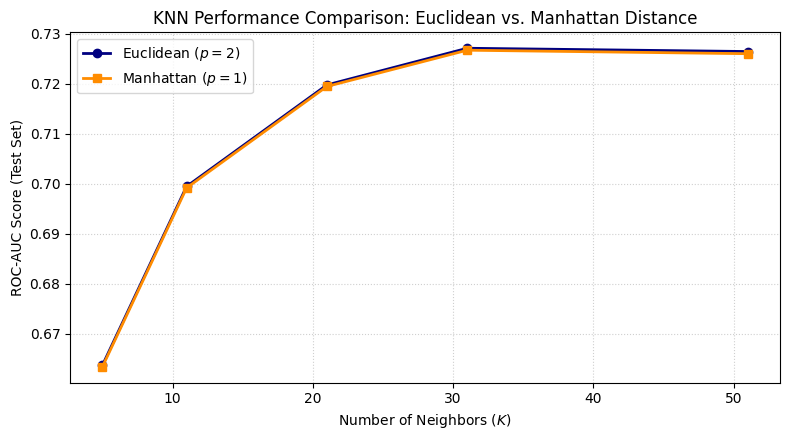

In [25]:
#visualizing performance across different values of K and distance metrics
k_values = [5, 11, 21, 31, 51]
euclidean_scores = []
manhattan_scores = []

for k in k_values:
  #euclidean (p=2)
  knn_e = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=2)
  knn_e.fit(Xs_train_scaled, ys_train)
  euclidean_scores.append(roc_auc_score(ys_test, knn_e.predict_proba(Xs_test_scaled)[:, 1]))
  
  #manhattan (p=1)
  knn_m = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=1)
  knn_m.fit(Xs_train_scaled, ys_train)
  manhattan_scores.append(roc_auc_score(ys_test, knn_m.predict_proba(Xs_test_scaled)[:, 1]))

plt.figure(figsize=(8, 4.5))
plt.plot(k_values, euclidean_scores, marker='o', label='Euclidean ($p=2$)', color='navy', linewidth=2)
plt.plot(k_values, manhattan_scores, marker='s', label='Manhattan ($p=1$)', color='darkorange', linewidth=2)
plt.title('KNN Performance Comparison: Euclidean vs. Manhattan Distance')
plt.xlabel('Number of Neighbors ($K$)')
plt.ylabel('ROC-AUC Score (Test Set)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Summary Thoughts:

Key Synthesis & Takeaways for Milestone TwoFeature Scaling Importance: Because KNN calculates direct the geometric distances between points, unscaled features like age vs. comorbidity count would disproportionately weight features with larger numerical ranges. Standardization(StandardScaler) ensures equal footing across all dimensions. 
Metric Sensitivity: Comparing Euclidean($p=2$) and Manhattan($p=1$) higlights how handling of outlier dimensions impacts classification. In clinical datasets where the isolated anomalous clinical readings can skew single axes, Manhattan distance often offers robust resilience against extreme values.

9.2 Activity: Jupyter Notebook – Gradient Boost


Week 9 Jupyter Notebook - Gradient Boost
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone Two, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions.  

For this week, include ideas such as gradient boost, learning rate, number of estimators, tree depth, and regularization. This homework should be submitted for peer review in the assignment titled 9.3 Peer Review: Week 9 Jupyter Notebook. Complete and submit your Jupyter Notebook homework by 11:59pm ET on Sunday. 

In Week 12, you will compile your findings from your Jupyter Notebook homework into your Milestone Two assignment for grading. For full instructions and the rubric for Milestone Two, refer to the following link. 

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [27]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset
support_cols = ['age', 'num.co', 'hospdead', 'dzclass']
df_s_subset = df[support_cols].copy()

support_numeric = ['age', 'num.co', 'hospdead']
for col in support_numeric:
  df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#one-hot encoding for categorical variable 'dzclass'
df_s_encoded = pd.get_dummies(
    df_s_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#define X(features) and y(binary target: hospdead)
X_s = df_s_encoded.drop(columns=['hospdead'])
y_s = df_s_encoded['hospdead']

#train-test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)

print('SUPPORT2 GRADIENT BOOSTING RESULTS\n' + '=' * 40)

#baseline gradient boosting classifier (default parameters: lr=0.1, n_estimators=100, max_depth=3)
gb_base = GradientBoostingClassifier(random_state=42)
gb_base.fit(Xs_train, ys_train)
ys_pred_base = gb_base.predict(Xs_test)
ys_prob_base = gb_base.predict_proba(Xs_test)[:, 1]

print('--- Baseline Gradient Boosting Performance ---')
print(classification_report(ys_test, ys_pred_base))
print(f'Baseline ROC-AUC: {roc_auc_score(ys_test, ys_prob_base):.4f}\n')

#regularized & tuned gradient boosting (smaller learning rate, more estimators, shallow depth, subsampling)
gb_tuned = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=4,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=42,
)
gb_tuned.fit(Xs_train, ys_train)
ys_pred_tuned = gb_tuned.predict(Xs_test)
ys_prob_tuned = gb_tuned.predict_proba(Xs_test)[:, 1]

print('Tuned & Regularized Gradient Boosting Performance')
print(classification_report(ys_test, ys_pred_tuned))
print(f'Tuned ROC-AUC: {roc_auc_score(ys_test, ys_prob_tuned):.4f}')

SUPPORT2 GRADIENT BOOSTING RESULTS
--- Baseline Gradient Boosting Performance ---
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1347
           1       0.60      0.13      0.21       474

    accuracy                           0.75      1821
   macro avg       0.68      0.55      0.53      1821
weighted avg       0.72      0.75      0.68      1821

Baseline ROC-AUC: 0.7348

Tuned & Regularized Gradient Boosting Performance
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1347
           1       0.61      0.13      0.22       474

    accuracy                           0.75      1821
   macro avg       0.68      0.55      0.53      1821
weighted avg       0.72      0.75      0.69      1821

Tuned ROC-AUC: 0.7367


Part 2: Diabetes 130-US Hospitals Dataset (Hospital Readmissions)
Working Research Question
How do sequential ensemble methods (Gradient Boosting) model 30-day readmissions (readmit_binary) using clinical intensity metrics, and how does varying the learning rate and number of estimators impact predictive accuracy?

In [28]:
#load DIABETES dataset (sampling 15,000 rows for efficient sequential tree building)
df_d = pd.read_csv('diabetic_data.csv').sample(n=15000, random_state=42)

diabetes_cols = [
    'time_in_hospital',
    'num_medications',
    'num_lab_procedures',
    'gender',
    'readmitted',
]
df_d_subset = df_d[diabetes_cols].copy()

numeric_cols = ['time_in_hospital', 'num_medications', 'num_lab_procedures']
for col in numeric_cols:
  df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#create binary target: 1 if readmitted < 30 days, 0 otherwise
df_d_subset['readmit_binary'] = (df_d_subset['readmitted'] == '<30').astype(int)
df_d_subset = df_d_subset.drop(columns=['readmitted'])

#one-hot encoding for "gender"
df_d_encoded = pd.get_dummies(
    df_d_subset, columns=['gender'], drop_first=True, dtype=int
)

#define X and y
X_d = df_d_encoded.drop(columns=['readmit_binary'])
y_d = df_d_encoded['readmit_binary']

#train-test split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

print('\nDIABETES GRADIENT BOOSTING RESULTS\n' + '=' * 40)

#gradient boosting classifier for diabetes dataset
gb_diabetes = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    min_samples_leaf=15,
    subsample=0.85,
    random_state=42,
)
gb_diabetes.fit(Xd_train, yd_train)
yd_pred_gb = gb_diabetes.predict(Xd_test)
yd_prob_gb = gb_diabetes.predict_proba(Xd_test)[:, 1]

print('Gradient Boosting Performance (Diabetes Dataset)')
print(classification_report(yd_test, yd_pred_gb))
print(f'Test Set ROC-AUC: {roc_auc_score(yd_test, yd_prob_gb):.4f}')


DIABETES GRADIENT BOOSTING RESULTS
Gradient Boosting Performance (Diabetes Dataset)
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      2674
           1       0.50      0.00      0.01       326

    accuracy                           0.89      3000
   macro avg       0.70      0.50      0.47      3000
weighted avg       0.85      0.89      0.84      3000

Test Set ROC-AUC: 0.5446


Part 3: Data Visualization (Learning Rate vs. Performance Comparison)

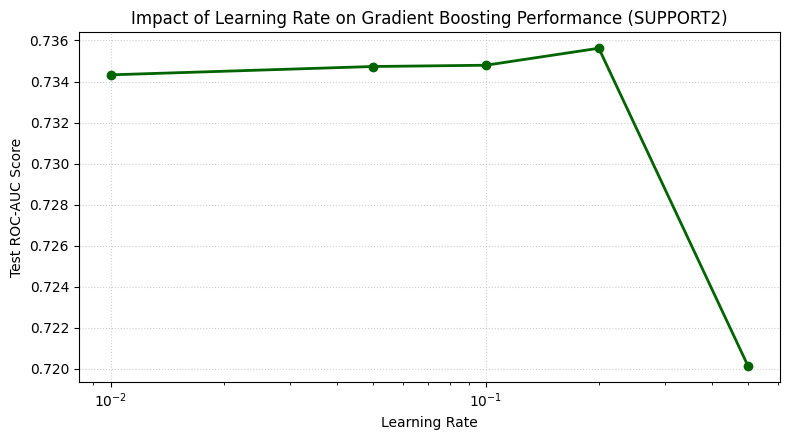

In [29]:
#visualizing impact of learning rate on test ROC-AUC score
learning_rates = [0.01, 0.05, 0.1, 0.2, 0.5]
auc_scores = []

for lr in learning_rates:
  gb_temp = GradientBoostingClassifier(
      n_estimators=100, learning_rate=lr, max_depth=3, random_state=42
  )
  gb_temp.fit(Xs_train, ys_train)
  prob = gb_temp.predict_proba(Xs_test)[:, 1]
  auc_scores.append(roc_auc_score(ys_test, prob))

plt.figure(figsize=(8, 4.5))
plt.plot(
    learning_rates,
    auc_scores,
    marker='o',
    color='darkgreen',
    linewidth=2,
)
plt.title('Impact of Learning Rate on Gradient Boosting Performance (SUPPORT2)')
plt.xlabel('Learning Rate')
plt.ylabel('Test ROC-AUC Score')
plt.xscale('log')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Key Synthesis & Takeaways for Milestone Two:

Sequential Error Correction: Unlike Random Forests which builds independent trees in parallel, Gradient Boosting constructs trees sequentially where each successive weak learner fits the residual errors of the preceding ensemble.

Learning Rate and Estimators Trade-off: Smaller learning rates (ex. $0.05$) combined with a higher number of estimators(n_estimators), allow for the model to make more gradual, precise corrections which often yield better generalization compared to the fast learning rates that risk overfitting early on.

Regularization Impact: Implementing subsampling(subsample=0.8) and leaf constraints(min_samples_leaf) successfully prevents individual decision stumps from memorizing any noise in critical care records.